In [1]:
import joblib
from sklearn.linear_model import Lasso
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')


In [2]:
from camda_functions_FRANCISCO import split_stratified_into_train_val_test, results_report, save_pickle_model

2026-02-16 10:37:26.194326: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-16 10:37:26.196354: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-02-16 10:37:26.234087: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-02-16 10:37:26.235152: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-16 10:37:26.896062: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Co

In [3]:
url ="https://raw.githubusercontent.com/EveliaCoss/CAMDA2025_metadatos/main/rawdata/TrainAndTest_cleaned/training_and_test_inputfile_cleaned.tsv.gz"
#https://raw.githubusercontent.com/EveliaCoss/CAMDA2025_metadatos/blob/main/rawdata/TrainAndTest_cleaned/training_and_test_inputfile_cleaned.tsv.gz
df = pd.read_csv(url, sep='\t', compression='gzip')
df["antibiotic"][df["antibiotic"]=="tetracycline"]="TET"

In [4]:
df_train = df[df["type"]=="training"]

## fijamos una bacteria y su respectivo antibiótico
especie = "Campylobacter"
antibiotico = "TET"

## Además vamos a fijar rutas de guardado, este debe especificar el modelo 
ruta_guardar_modelos = "modelos_fenotipo"

In [5]:
#los que aparecen mas de una vez
#vals=[0.015, 1.000, 8.000, 0.250, 0.030, 0.060, 16.000, 0.120, 4.000, 0.125, 32.000, 2.000, 0.500, 0.004, 0.016, 0.002, 0.032, 64.000, 0.380, 0.008, 12.000]

to_predict = df[df["measurement_value"].isna()]
to_predict_Ciprofloxacin = to_predict[to_predict["antibiotic"]=="ciprofloxacin"]
to_predict_Meropenem = to_predict[to_predict["antibiotic"]=="meropenem"]
DF_train= df[df["measurement_value"].isin(vals)]
DF_Ciprofloxacin= DF_train[DF_train["antibiotic"]=="ciprofloxacin"]
DF_Meropenem= DF_train[DF_train["antibiotic"]=="meropenem"]

to_predict[to_predict["genus"]=="Pseudomonas"]

In [6]:
def encode_labels(dataframe):
    """
    Encodes the labels in the specified column of the dataframe.
    
    Parameters:
    - dataframe: The input dataframe.
    
    Returns:
    - encoded_labels: The encoded labels.
    - label_encoder: The label encoder used for encoding.
    """
    labels = dataframe.iloc[:, 5]
    label_encoder = LabelEncoder()
    
    # Fit and transform the labels
    encoded_labels = label_encoder.fit_transform(labels)
    
    return encoded_labels, label_encoder


In [7]:
def get_alpha(X_train, y_train, X_test, y_test, cv=10, random_state=42):
    """
    Finds the best alpha for Lasso regression using cross-validation, fits the final model,
    and evaluates the model on both training and testing data.

    Parameters:
    - X_train: Training feature data.
    - y_train: Training target data.
    - X_test: Testing feature data.
    - y_test: Testing target data.
    - cv: Number of cross-validation folds (default is 10).
    - random_state: Random state for reproducibility (default is 42).

    Returns:
    - final_model: The fitted Lasso model with the best alpha.
    - best_alpha: The best alpha value found by LassoCV.
    """
    alphas = np.logspace(-7, 7, 100)

    # Set up the LassoCV model
    lasso_cv = LassoCV(alphas=alphas, cv=cv, random_state=random_state)

    # Fit the model on the training data
    lasso_cv.fit(X_train, y_train)

    # Retrieve the best alpha value
    best_alpha = lasso_cv.alpha_
    print(f"The best alpha value is: {best_alpha}")

    # Train a final Lasso model using the best alpha
    final_model = Lasso(alpha=best_alpha)
    final_model.fit(X_train, y_train)

    # Evaluate the model
    training_score = final_model.score(X_train, y_train)
    testing_score = final_model.score(X_test, y_test)
    print(f"Training score: {training_score}")
    print(f"Testing score: {testing_score}")

    return final_model, best_alpha

# Example usage:
# Assuming you have already split your data into X_train, X_test, y_train, and y_test
# final_model, best_alpha = get_alpha(X_train, y_train, X_test, y_test)


In [8]:


def evaluate_model(model, X_test, y_test):
    """
    Evaluates the model using the test data and plots the confusion matrix.

    Parameters:
    - model: The trained model.
    - X_test: The test feature data.
    - y_test: The true labels for the test data.

    Returns:
    - accuracy: The accuracy of the model.
    - f1: The F1 score of the model.
    - conf_matrix: The confusion matrix.
    """
    # Predict continuous values
    y_pred_continuous = model.predict(X_test)
    
    # Encode predicted labels
    label_encoder = LabelEncoder()
    y_pred_encoded = label_encoder.fit_transform(y_pred_continuous)
    
    # Calculate the confusion matrix
    conf_matrix = confusion_matrix(y_test, y_pred_encoded)
    accuracy = accuracy_score(y_test, y_pred_encoded)
    #f1 = f1_score(y_test, y_pred_encoded, average='weighted')  # Specify average parameter
    
    # Print the accuracy and F1 score
    print(f"Accuracy: {accuracy:.2f}")
    #print(f"F1 Score: {f1:.2f}")
    
    # Plot the confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()
    
    return accuracy, conf_matrix

# Example usage:
# Assuming you have a trained model and test data
# accuracy, f1, conf_matrix = evaluate_model(modelo, X_test, y_test)


In [9]:
# Plotting
def plot_true_vs_pred(y_true, y_pred, title='True vs Predicted Values'):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_true, y=y_pred)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], '--r')
    plt.xlabel('True Values')
    plt.ylabel('Predicted Values')
    plt.title(title)
    plt.show()

In [10]:
def lasso_summary(model, X_train, y_train, X_test, y_test):
    """
    Prints a summary of the Lasso model.
    
    Parameters:
    - model: The trained Lasso model.
    - X_train: Training features.
    - y_train: Training target.
    - X_test: Test features.
    - y_test: Test target.
    """
    # Coefficients
    #print("Coefficients:")
    #for name, coef in zip(X_train.columns, model.coef_):
        #print(f"{name}: {coef:.4f}")

    # Intercept
    print(f"\nIntercept: {model.intercept_:.4f}")

    # Model performance
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    print("\nPerformance on Training Data:")
    print(f"Mean Squared Error: {mean_squared_error(y_train, y_pred_train):.4f}")
    print(f"R2 Score: {r2_score(y_train, y_pred_train):.4f}")

    print("\nPerformance on Test Data:")
    print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred_test):.4f}")
    print(f"R2 Score: {r2_score(y_test, y_pred_test):.4f}")

    # Print the non-zero coefficients
    non_zero_coef = np.sum(model.coef_ != 0)
    print(f"\nNumber of non-zero coefficients: {non_zero_coef}")

# Print the summary of the Lasso model
#lasso_summary(lasso, X_train, y_train, X_test, y_test)


In [11]:
def make_prediction(model, to_predict, threshold=0.5):
    """
    Make predictions on the given data using the provided model, 
    and save the predictions to a CSV file.

    Parameters:
    - model: The trained model used for making predictions.
    - to_predict: The DataFrame containing the data to predict on.
    - threshold: The threshold for converting continuous predictions to binary classes.

    Returns:
    - test_predictions_df: A DataFrame containing the predictions.
    """
    # Make predictions
    y_test_pred_continuous = model.predict(to_predict)#.iloc[:, 6:])
    y_test_pred_binary = (y_test_pred_continuous >= threshold).astype(int)
    
    # Map binary predictions to labels
    #Lab_predicted = ['Susceptible' if i == 1 else 'Resistant' for i in y_test_pred_binary]
    Lab_predicted = y_test_pred_binary
    # Create a DataFrame with the predictions
    test_predictions_df = pd.DataFrame({'status': Lab_predicted })
        #'genus': to_predict['genus'],
        #'species': to_predict['species'],
        #'accession': to_predict['accession'],
        #'antibiotic': to_predict['antibiotic'],
        
    

    return test_predictions_df

In [12]:
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score,
    recall_score, f1_score
)

def evaluar_clasificacion_binaria(y_true, y_pred, etiquetas=["Suceptible", "Resistente"], titulo="Matriz de Confusión"):
    """
    Grafica la matriz de confusión y muestra las métricas de clasificación binaria.

    Args:
        y_true (array-like): Valores reales de la clase.
        y_pred (array-like): Predicciones del modelo.
        etiquetas (list): Nombres de las clases en orden [clase 0, clase 1].
        titulo (str): Título para la gráfica.
    """

    # Asegúrate de que sean arreglos de enteros
    y_true = np.array(y_true).astype(int)
    y_pred = np.array(y_pred).astype(int)

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title(titulo)
    plt.show()

    # Métricas
    print("=== MÉTRICAS DE CLASIFICACIÓN ===")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred):.3f}")
    print(f"Recall   : {recall_score(y_true, y_pred):.3f}")
    print(f"F1-score : {f1_score(y_true, y_pred):.3f}")
    print("\n=== REPORTE DETALLADO ===")
    print(classification_report(y_true, y_pred, target_names=etiquetas))


In [14]:
## dividir los datos y buscar alfa
columnas_a_excluir = ['genus', 'accession','scientific_name_new', 'species', 'genome', 'ani', 'phenotype_assigned' ,'phenotype', 
                        'antibiotic', 'measurement_value', 'type',  'recategorized_mic'] #'assign_phenotype',
X = df_train.drop(columnas_a_excluir, axis=1)

X_with_nan = X[X.isna().any(axis=1)]
#X_with_nan.index # [186, 1648, 1747, 2423, 2427, 2434, 3122, 3123, 3191, 3584]
y = df_train["phenotype_assigned"]


#df_train_clean = df_train.drop(index=X_with_nan.index)
#X = df_train_clean.drop(columnas_a_excluir, axis=1)

#y = df_train_clean["assign_phenotype"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


X_train, y_train, __, __, X_test, y_test, class_w, __ = \
        split_stratified_into_train_val_test(X, y_encoded, .80, 0, .20, 
        std=False, two_subsets=True, random_state=42)



In [15]:
best_alpha = get_alpha(X_train, y_train, X_test, y_test, cv=10, random_state=42)
print(best_alpha)

The best alpha value is: 0.0002477076355991709
Training score: 0.7111555814272124
Testing score: 0.6513354970891643
(Lasso(alpha=0.0002477076355991709), 0.0002477076355991709)


In [16]:
best_alpha[1]

0.0002477076355991709

In [17]:
modelo = Lasso(alpha=best_alpha[1])

In [18]:
modelo.fit(X_train, y_train)

Lasso(alpha=0.0002477076355991709)

In [19]:
ruta_guardar_modelo= "modelos_fenotipo/"
nombre = "LASSO_completo"
save_pickle_model(modelo, ruta_guardar_modelo, nombre)

In [20]:
lasso_summary(modelo, X_train, y_train, X_test, y_test)



Intercept: 0.3443

Performance on Training Data:
Mean Squared Error: 0.1110
R2 Score: 0.7112

Performance on Test Data:
Mean Squared Error: 0.1342
R2 Score: 0.6513

Number of non-zero coefficients: 270


In [21]:
y_pred=make_prediction(modelo, X_test, threshold=0.5)


In [22]:
y_test.uni

AttributeError: 'numpy.ndarray' object has no attribute 'uni'

In [23]:
df_train["phenotype_assigned"].value_counts()#[df["phenotype_assigned"]=="tetracycline"]

phenotype_assigned
Susceptible    2726
Resistant      2396
Name: count, dtype: int64

In [24]:
y_pred.value_counts()

status
1         677
0         434
Name: count, dtype: int64

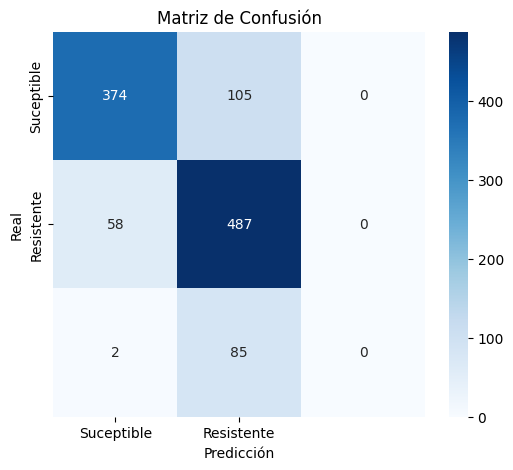

=== MÉTRICAS DE CLASIFICACIÓN ===
Accuracy : 0.775


ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].

In [25]:
evaluar_clasificacion_binaria(y_test, y_pred)

# HASTA AQUÍ EL CODIGO

exclude_indices = [0, 5]
####Get column names
exclude_columns = to_predict.columns[exclude_indices]
dataframe_2= to_predict.drop(columns=exclude_columns)
MIC_Lab=final_model.predict(to_predict.drop)

In [ ]:
def predict_with_exclusions(model, data, exclude_indices):
    """
    Make predictions on the given data using the provided model, excluding specified columns.

    Parameters:
    - model: The trained model used for making predictions.
    - data: The DataFrame containing the data to predict on.
    - exclude_indices: List of column indices to exclude.

    Returns:
    - predictions: The predictions made by the model.
    """
    # Get the column names for the indices
    exclude_columns = data.columns[exclude_indices]

    # Drop the specified columns from the DataFrame
    dataframe_2 = data.drop(columns=exclude_columns)

    # Make predictions using the model
    predictions = model.predict(dataframe_2)

    return predictions

# Example usage:
# Assuming you have a trained model `final_model` and data `to_predict`
#exclude_indices = [0,3,5]
#MIC_Lab = predict_with_exclusions(final_model, to_predict, exclude_indices)
#print(MIC_Lab)

In [ ]:
#codifica variables categoricas y usalas para PREDECIR

col_1 = to_predict.iloc[:,1]
col_2 = to_predict.iloc[:,2]
#col_3 = to_predict.iloc[:,3]
col_3 =Lab_pop
col_4 = to_predict.iloc[:,4]
label_encoder = LabelEncoder()
    
    # Fit and transform the labels
col_1_encoder = label_encoder.fit_transform(col_1)
col_2_encoder = label_encoder.fit_transform(col_2)
col_3_encoder = label_encoder.fit_transform(col_3)
col_4_encoder = label_encoder.fit_transform(col_4)

to_predict["genus"]=col_1_encoder
to_predict["species"]=col_2_encoder
to_predict["phenotype"]=col_3_encoder
to_predict["antibiotic"]=col_4_encoder

In [ ]:
exclude_indices = [0, 5]
MIC_Lab = predict_with_exclusions(final_model, to_predict, exclude_indices)
print(np.exp(MIC_Lab))

In [ ]:
DT["MIC"]=np.round(np.exp(MIC_Lab),3)

In [ ]:
#DT[(DT["status"]=="Susceptible") & (DT["MIC"]>2)]

In [ ]:
DT.to_csv(os.path.join("Resultados_Lasso", "First_prediction_Lasso.csv"), index=False)

In [ ]:
print(Lab_haydee_encoded)

print(Lab_victor_encoded)
count= 0
for i in range(1820):
    if DT_hay["status"][i]==DT_vic["status"][i]:
        count=count+1
    else: count=count
print(count)

In [ ]:
otras_etiquetas

In [ ]:
otras_etiquetas = pd.read_csv("predicciones_actual2.csv")
Lab_haydee= otras_etiquetas["umap+tfidf KNN5"]
Lab_victor=otras_etiquetas["phenotype"]

Lab_haydee_encoded=label_encoder.fit_transform(Lab_haydee)
Lab_victor_encoded=label_encoder.fit_transform(Lab_victor)

to_predict["phenotype"]=Lab_haydee_encoded
print(to_predict["phenotype"].value_counts())
Haydee = predict_with_exclusions(final_model, to_predict, exclude_indices)
print(np.exp(Haydee))
DT["MIC"]=np.round(np.exp(Haydee),3)
DT["status"]=Lab_haydee
DT.to_csv(os.path.join("Resultados_Lasso", "Haydee.csv"), index=False)
DT_hay=DT



In [ ]:
Lab_victor=otras_etiquetas["phenotype"]
Lab_victor_encoded=label_encoder.fit_transform(Lab_victor)
to_predict["phenotype"]=Lab_victor_encoded
print(to_predict["phenotype"].value_counts())
Victor= predict_with_exclusions(final_model, to_predict, exclude_indices)
print(np.exp(Victor))
DT["MIC"]=np.round(np.exp(Victor),3)
DT["status"]=Lab_victor
DT.to_csv(os.path.join("Resultados_Lasso", "Victor.csv"), index=False)
DT_vic=DT

In [ ]:
most_pop=pd.read_csv("most_pop.csv")

In [ ]:
most_pop

In [ ]:
Lab_pop=most_pop["most_frequent_value"]

Lab_pop_encoded=label_encoder.fit_transform(Lab_pop)
to_predict["phenotype"]=Lab_pop_encoded
print(to_predict["phenotype"].value_counts())
Pop = predict_with_exclusions(final_model, to_predict, exclude_indices)
print(np.exp(Pop))
DT["MIC"]=np.round(np.exp(Pop),3)
DT["status"]=Lab_pop
DT.to_csv(os.path.join("Resultados_Lasso", "POP.csv"), index=False)
DT_pop=DT


In [ ]:
np.where(y_pred_test>100)

In [ ]:
y_test[796]

In [ ]:
y_pred_continuous = modelo.predict(X_test)

In [ ]:


def evaluate_model(model, X_test, y_test):
    """
    Evaluates the model using the test data and plots the predictions vs. actual values.

    Parameters:
    - model: The trained model.
    - X_test: The test feature data.
    - y_test: The true labels for the test data.

    Returns:
    - mae: The mean absolute error of the model.
    - mse: The mean squared error of the model.
    - rmse: The root mean squared error of the model.
    - r2: The R-squared score of the model.
    """
    # Predict continuous values
    y_pred = model.predict(X_test)
    y_pred= np.exp(y_pred)
    y_test= np.exp(y_test)
    
    # Calculate regression metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Print the regression metrics
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"Mean Squared Error (MSE): {mse:.2f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
    print(f"R-squared (R²): {r2:.2f}")
    
    # Plot the predictions vs. actual values
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
    plt.title('Predictions vs. Actual Values')
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.show()
    
    return mae, mse, rmse, r2


In [ ]:
mae, mse, rmse, r2 = evaluate_model(final_model, X_test, y_test)
